This code runs a GLM analysis to analyze correlation between motoneurons over days

In [1]:
import os
import re  
import math
import pickle
import zipfile
from collections import defaultdict

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d import Axes3D  

import h5py
from scipy import signal
from scipy.stats import (zscore, ks_2samp, linregress, pearsonr)
from scipy.signal import (convolve, windows, resample)
from scipy.ndimage import gaussian_filter1d

from sklearn.preprocessing import (PolynomialFeatures, StandardScaler)
from sklearn.model_selection import (train_test_split, cross_val_score, KFold,GridSearchCV)


from scipy.signal import convolve, windows
from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from pyglmnet import GLM


from sklearn.linear_model import PoissonRegressor
from sklearn.pipeline import make_pipeline
from scipy.interpolate import interp1d

from scipy.special import gammaln

from scipy.stats import poisson, chisquare


In [2]:
session_files1 = {
    "Day01": [
        'E3_MB01_Day01High_1.pkl', 'E3_MB01_Day01High_11.pkl', 'E3_MB01_Day01High_14.pkl',
        'E3_MB01_Day01High_17.pkl', 'E3_MB01_Day01High_21.pkl', 'E3_MB01_Day01High_24.pkl',
        'E3_MB01_Day01High_27.pkl', 'E3_MB01_Day01High_30.pkl', 'E3_MB01_Day01High_6.pkl',
        'E3_MB01_Day01High_9.pkl'
    ],
    "Day03": [
        'E3_MB01_Day03High_11.pkl', 'E3_MB01_Day03High_14.pkl', 'E3_MB01_Day03High_18.pkl',
        'E3_MB01_Day03High_21.pkl', 'E3_MB01_Day03High_23.pkl', 'E3_MB01_Day03High_26.pkl',
        'E3_MB01_Day03High_29.pkl', 'E3_MB01_Day03High_3.pkl', 'E3_MB01_Day03High_4.pkl',
        'E3_MB01_Day03High_9.pkl'
    ],
    "Day04": [
        'E3_MB01_Day04High_1.pkl', 'E3_MB01_Day04High_10.pkl', 'E3_MB01_Day04High_13.pkl',
        'E3_MB01_Day04High_17.pkl', 'E3_MB01_Day04High_20.pkl', 'E3_MB01_Day04High_23.pkl',
        'E3_MB01_Day04High_25.pkl', 'E3_MB01_Day04High_29.pkl', 'E3_MB01_Day04High_30.pkl',
        'E3_MB01_Day04High_6.pkl', 'E3_MB01_Day04High_9.pkl'
    ],
    "Day05": [
        'E3_MB01_Day05High_1.pkl', 'E3_MB01_Day05High_10.pkl', 'E3_MB01_Day05High_13.pkl',
        'E3_MB01_Day05High_18.pkl', 'E3_MB01_Day05High_21.pkl', 'E3_MB01_Day05High_23.pkl',
        'E3_MB01_Day05High_26.pkl', 'E3_MB01_Day05High_28.pkl', 'E3_MB01_Day05High_5.pkl',
        'E3_MB01_Day05High_9.pkl'
    ],
    "Day06": [
        'E3_MB01_Day06High_10.pkl', 'E3_MB01_Day06High_14.pkl', 'E3_MB01_Day06High_18.pkl',
        'E3_MB01_Day06High_21.pkl', 'E3_MB01_Day06High_22.pkl', 'E3_MB01_Day06High_26.pkl',
        'E3_MB01_Day06High_3.pkl', 'E3_MB01_Day06High_30.pkl', 'E3_MB01_Day06High_5.pkl',
        'E3_MB01_Day06High_9.pkl'
    ],
    "Day07": [
        'E3_MB01_Day07High_1.pkl', 'E3_MB01_Day07High_10.pkl', 'E3_MB01_Day07High_14.pkl',
        'E3_MB01_Day07High_18.pkl', 'E3_MB01_Day07High_19.pkl', 'E3_MB01_Day07High_23.pkl',
        'E3_MB01_Day07High_26.pkl', 'E3_MB01_Day07High_28.pkl', 'E3_MB01_Day07High_5.pkl',
        'E3_MB01_Day07High_9.pkl'
        
    ],
    
    "Day08": ['E3_MB01_Day08High_12.pkl', 'E3_MB01_Day08High_13.pkl', 'E3_MB01_Day08High_17.pkl',
              'E3_MB01_Day08High_21.pkl', 'E3_MB01_Day08High_23.pkl', 'E3_MB01_Day08High_25.pkl',
              'E3_MB01_Day08High_3.pkl', 'E3_MB01_Day08High_30.pkl', 'E3_MB01_Day08High_7.pkl'],
    "Day09": ['E3_MB01_Day09High_1.pkl', 'E3_MB01_Day09High_13.pkl', 'E3_MB01_Day09High_15.pkl',
              'E3_MB01_Day09High_18.pkl', 'E3_MB01_Day09High_23.pkl', 'E3_MB01_Day09High_26.pkl',
              'E3_MB01_Day09High_27.pkl', 'E3_MB01_Day09High_4.pkl', 'E3_MB01_Day09High_8.pkl',
              'E3_MB01_Day09High_9.pkl'],
    "Day10": ['E3_MB01_Day10High_1.pkl', 'E3_MB01_Day10High_10.pkl', 'E3_MB01_Day10High_15.pkl',
              'E3_MB01_Day10High_18.pkl', 'E3_MB01_Day10High_19.pkl', 'E3_MB01_Day10High_22.pkl',
              'E3_MB01_Day10High_25.pkl', 'E3_MB01_Day10High_30.pkl', 'E3_MB01_Day10High_5.pkl',
              'E3_MB01_Day10High_7.pkl'],
    "Day11": ['E3_MB01_Day11High_12.pkl', 'E3_MB01_Day11High_15.pkl', 'E3_MB01_Day11High_18.pkl',
              'E3_MB01_Day11High_20.pkl', 'E3_MB01_Day11High_24.pkl', 'E3_MB01_Day11High_25.pkl',
              'E3_MB01_Day11High_28.pkl', 'E3_MB01_Day11High_3.pkl', 'E3_MB01_Day11High_4.pkl',
              'E3_MB01_Day11High_8.pkl'],
    "Day12": ['E3_MB01_Day12High_12.pkl', 'E3_MB01_Day12High_15.pkl', 'E3_MB01_Day12High_17.pkl',
              'E3_MB01_Day12High_2.pkl', 'E3_MB01_Day12High_20.pkl', 'E3_MB01_Day12High_24.pkl',
              'E3_MB01_Day12High_25.pkl', 'E3_MB01_Day12High_28.pkl', 'E3_MB01_Day12High_4.pkl',
              'E3_MB01_Day12High_7.pkl'],
    "Day13": ['E3_MB01_Day13High_1.pkl', 'E3_MB01_Day13High_12.pkl', 'E3_MB01_Day13High_14.pkl',
              'E3_MB01_Day13High_16.pkl', 'E3_MB01_Day13High_19.pkl', 'E3_MB01_Day13High_23.pkl',
              'E3_MB01_Day13High_25.pkl', 'E3_MB01_Day13High_30.pkl', 'E3_MB01_Day13High_5.pkl',
              'E3_MB01_Day13High_9.pkl'],
    "Day14": ['E3_MB01_Day14High_12.pkl', 'E3_MB01_Day14High_15.pkl', 'E3_MB01_Day14High_18.pkl',
              'E3_MB01_Day14High_19.pkl', 'E3_MB01_Day14High_22.pkl', 'E3_MB01_Day14High_26.pkl',
              'E3_MB01_Day14High_28.pkl', 'E3_MB01_Day14High_3.pkl', 'E3_MB01_Day14High_5.pkl',
              'E3_MB01_Day14High_8.pkl']

}



#######################





session_files3 = {
    "Day01": ['E3_MB03_Day01High_12.pkl', 'E3_MB03_Day01High_14.pkl', 'E3_MB03_Day01High_16.pkl',
              'E3_MB03_Day01High_19.pkl', 'E3_MB03_Day01High_23.pkl', 'E3_MB03_Day01High_27.pkl',
              'E3_MB03_Day01High_29.pkl', 'E3_MB03_Day01High_3.pkl', 'E3_MB03_Day01High_4.pkl',
              'E3_MB03_Day01High_8.pkl'],
    "Day02": ['E3_MB03_Day02High_12.pkl', 'E3_MB03_Day02High_15.pkl', 'E3_MB03_Day02High_17.pkl',
              'E3_MB03_Day02High_19.pkl', 'E3_MB03_Day02High_2.pkl', 'E3_MB03_Day02High_24.pkl',
              'E3_MB03_Day02High_26.pkl', 'E3_MB03_Day02High_29.pkl', 'E3_MB03_Day02High_6.pkl',
              'E3_MB03_Day02High_8.pkl'],
    "Day03": ['E3_MB03_Day03High_10.pkl', 'E3_MB03_Day03High_15.pkl', 'E3_MB03_Day03High_17.pkl',
              'E3_MB03_Day03High_2.pkl', 'E3_MB03_Day03High_21.pkl', 'E3_MB03_Day03High_23.pkl',
              'E3_MB03_Day03High_26.pkl', 'E3_MB03_Day03High_29.pkl', 'E3_MB03_Day03High_5.pkl',
              'E3_MB03_Day03High_9.pkl'],
    "Day04": ['E3_MB03_Day04High_1.pkl', 'E3_MB03_Day04High_11.pkl', 'E3_MB03_Day04High_15.pkl',
              'E3_MB03_Day04High_16.pkl', 'E3_MB03_Day04High_20.pkl', 'E3_MB03_Day04High_23.pkl',
              'E3_MB03_Day04High_26.pkl', 'E3_MB03_Day04High_28.pkl', 'E3_MB03_Day04High_4.pkl',
              'E3_MB03_Day04High_9.pkl'],
    "Day05": ['E3_MB03_Day05High_12.pkl', 'E3_MB03_Day05High_15.pkl', 'E3_MB03_Day05High_17.pkl',
              'E3_MB03_Day05High_20.pkl', 'E3_MB03_Day05High_22.pkl', 'E3_MB03_Day05High_26.pkl',
              'E3_MB03_Day05High_29.pkl', 'E3_MB03_Day05High_3.pkl', 'E3_MB03_Day05High_4.pkl',
              'E3_MB03_Day05High_7.pkl'],
    "Day07": ['E3_MB03_Day07High_11.pkl', 'E3_MB03_Day07High_13.pkl', 'E3_MB03_Day07High_18.pkl',
              'E3_MB03_Day07High_19.pkl', 'E3_MB03_Day07High_22.pkl', 'E3_MB03_Day07High_27.pkl',
              'E3_MB03_Day07High_29.pkl', 'E3_MB03_Day07High_3.pkl', 'E3_MB03_Day07High_7.pkl'],
    "Day10": ['E3_MB03_Day10High_12.pkl', 'E3_MB03_Day10High_13.pkl', 'E3_MB03_Day10High_17.pkl',
              'E3_MB03_Day10High_21.pkl', 'E3_MB03_Day10High_22.pkl', 'E3_MB03_Day10High_25.pkl',
              'E3_MB03_Day10High_3.pkl', 'E3_MB03_Day10High_30.pkl', 'E3_MB03_Day10High_5.pkl',
              'E3_MB03_Day10High_8.pkl'],
    "Day11": ['E3_MB03_Day11High_10.pkl', 'E3_MB03_Day11High_14.pkl', 'E3_MB03_Day11High_18.pkl',
              'E3_MB03_Day11High_20.pkl', 'E3_MB03_Day11High_23.pkl', 'E3_MB03_Day11High_26.pkl',
              'E3_MB03_Day11High_3.pkl', 'E3_MB03_Day11High_30.pkl', 'E3_MB03_Day11High_6.pkl',
              'E3_MB03_Day11High_9.pkl'],
    "Day12": ['E3_MB03_Day12High_12.pkl', 'E3_MB03_Day12High_13.pkl', 'E3_MB03_Day12High_17.pkl',
              'E3_MB03_Day12High_21.pkl', 'E3_MB03_Day12High_22.pkl', 'E3_MB03_Day12High_25.pkl',
              'E3_MB03_Day12High_29.pkl', 'E3_MB03_Day12High_3.pkl', 'E3_MB03_Day12High_5.pkl',
              'E3_MB03_Day12High_8.pkl'],
    "Day13": ['E3_MB03_Day13High_12.pkl', 'E3_MB03_Day13High_13.pkl', 'E3_MB03_Day13High_18.pkl',
              'E3_MB03_Day13High_19.pkl', 'E3_MB03_Day13High_2.pkl', 'E3_MB03_Day13High_24.pkl',
              'E3_MB03_Day13High_27.pkl', 'E3_MB03_Day13High_29.pkl', 'E3_MB03_Day13High_5.pkl',
              'E3_MB03_Day13High_7.pkl'],
    "Day14": ['E3_MB03_Day14High_12.pkl', 'E3_MB03_Day14High_13.pkl', 'E3_MB03_Day14High_16.pkl',
              'E3_MB03_Day14High_21.pkl', 'E3_MB03_Day14High_24.pkl', 'E3_MB03_Day14High_26.pkl',
              'E3_MB03_Day14High_29.pkl', 'E3_MB03_Day14High_3.pkl', 'E3_MB03_Day14High_4.pkl',
              'E3_MB03_Day14High_8.pkl']
}


#######################



session_files2 = {
    "Day02": [
        'E3_MB02_Day02High_10.pkl', 'E3_MB02_Day02High_14.pkl', 'E3_MB02_Day02High_18.pkl',
        'E3_MB02_Day02High_2.pkl', 'E3_MB02_Day02High_20.pkl', 'E3_MB02_Day02High_24.pkl',
        'E3_MB02_Day02High_27.pkl', 'E3_MB02_Day02High_29.pkl', 'E3_MB02_Day02High_6.pkl',
        'E3_MB02_Day02High_9.pkl'
    ],
    "Day03": [
        'E3_MB02_Day03High_11.pkl', 'E3_MB02_Day03High_13.pkl', 'E3_MB02_Day03High_18.pkl',
        'E3_MB02_Day03High_21.pkl', 'E3_MB02_Day03High_24.pkl', 'E3_MB02_Day03High_26.pkl',
        'E3_MB02_Day03High_29.pkl', 'E3_MB02_Day03High_3.pkl', 'E3_MB02_Day03High_5.pkl',
        'E3_MB02_Day03High_7.pkl'
    ],
    "Day04": [
        'E3_MB02_Day04High_11.pkl', 'E3_MB02_Day04High_14.pkl', 'E3_MB02_Day04High_16.pkl',
        'E3_MB02_Day04High_2.pkl', 'E3_MB02_Day04High_21.pkl', 'E3_MB02_Day04High_22.pkl',
        'E3_MB02_Day04High_27.pkl', 'E3_MB02_Day04High_30.pkl', 'E3_MB02_Day04High_5.pkl',
        'E3_MB02_Day04High_7.pkl'
    ],
    "Day07": [
        'E3_MB02_Day07High_1.pkl', 'E3_MB02_Day07High_12.pkl', 'E3_MB02_Day07High_13.pkl',
        'E3_MB02_Day07High_16.pkl', 'E3_MB02_Day07High_19.pkl', 'E3_MB02_Day07High_24.pkl',
        'E3_MB02_Day07High_27.pkl', 'E3_MB02_Day07High_30.pkl', 'E3_MB02_Day07High_4.pkl',
        'E3_MB02_Day07High_9.pkl'
    ],
    "Day13": [
        'E3_MB02_Day13High_1.pkl', 'E3_MB02_Day13High_11.pkl', 'E3_MB02_Day13High_13.pkl',
        'E3_MB02_Day13High_18.pkl', 'E3_MB02_Day13High_20.pkl', 'E3_MB02_Day13High_23.pkl',
        'E3_MB02_Day13High_26.pkl', 'E3_MB02_Day13High_28.pkl', 'E3_MB02_Day13High_4.pkl',
        'E3_MB02_Day13High_8.pkl'
    ]
}



#######################




session_files4 = {
    "Day01": ['E3_MB04_Day01High_16.pkl', 'E3_MB04_Day01High_19.pkl', 'E3_MB04_Day01High_2.pkl',
              'E3_MB04_Day01High_24.pkl', 'E3_MB04_Day01High_26.pkl', 'E3_MB04_Day01High_30.pkl',
              'E3_MB04_Day01High_6.pkl', 'E3_MB04_Day01High_8.pkl'],
    "Day03": ['E3_MB04_Day03High_10.pkl', 'E3_MB04_Day03High_14.pkl', 'E3_MB04_Day03High_17.pkl',
              'E3_MB04_Day03High_19.pkl', 'E3_MB04_Day03High_22.pkl', 'E3_MB04_Day03High_27.pkl',
              'E3_MB04_Day03High_28.pkl', 'E3_MB04_Day03High_3.pkl', 'E3_MB04_Day03High_5.pkl',
              'E3_MB04_Day03High_8.pkl'],
    "Day07": ['E3_MB04_Day07High_15.pkl', 'E3_MB04_Day07High_29.pkl', 'E3_MB04_Day07High_6.pkl',
              'E3_MB04_Day07High_8.pkl'],
    "Day08": ['E3_MB04_Day08High_11.pkl', 'E3_MB04_Day08High_13.pkl', 'E3_MB04_Day08High_18.pkl',
              'E3_MB04_Day08High_19.pkl', 'E3_MB04_Day08High_2.pkl', 'E3_MB04_Day08High_22.pkl',
              'E3_MB04_Day08High_27.pkl', 'E3_MB04_Day08High_28.pkl', 'E3_MB04_Day08High_6.pkl',
              'E3_MB04_Day08High_9.pkl'],
    "Day09": ['E3_MB04_Day09High_1.pkl', 'E3_MB04_Day09High_19.pkl', 'E3_MB04_Day09High_24.pkl',
              'E3_MB04_Day09High_27.pkl', 'E3_MB04_Day09High_30.pkl', 'E3_MB04_Day09High_6.pkl'],
    "Day10": ['E3_MB04_Day10High_11.pkl', 'E3_MB04_Day10High_15.pkl', 'E3_MB04_Day10High_17.pkl',
              'E3_MB04_Day10High_2.pkl', 'E3_MB04_Day10High_21.pkl', 'E3_MB04_Day10High_22.pkl',
              'E3_MB04_Day10High_26.pkl', 'E3_MB04_Day10High_28.pkl', 'E3_MB04_Day10High_4.pkl',
              'E3_MB04_Day10High_9.pkl'],
    "Day11": ['E3_MB04_Day11High_10.pkl', 'E3_MB04_Day11High_14.pkl', 'E3_MB04_Day11High_16.pkl',
              'E3_MB04_Day11High_2.pkl', 'E3_MB04_Day11High_21.pkl', 'E3_MB04_Day11High_23.pkl',
              'E3_MB04_Day11High_27.pkl', 'E3_MB04_Day11High_28.pkl', 'E3_MB04_Day11High_4.pkl',
              'E3_MB04_Day11High_9.pkl'],
    
    "Day12": ['E3_MB04_Day12High_2.pkl', 'E3_MB04_Day12High_5.pkl', 'E3_MB04_Day12High_9.pkl',
              'E3_MB04_Day12High_12.pkl', 'E3_MB04_Day12High_14.pkl', 'E3_MB04_Day12High_18.pkl',
              'E3_MB04_Day12High_19.pkl', 'E3_MB04_Day12High_23.pkl', 'E3_MB04_Day12High_26.pkl',
              'E3_MB04_Day12High_29.pkl'],
        
    "Day13": ['E3_MB04_Day13High_3.pkl', 'E3_MB04_Day13High_4.pkl', 'E3_MB04_Day13High_8.pkl',
              'E3_MB04_Day13High_12.pkl', 'E3_MB04_Day13High_14.pkl', 'E3_MB04_Day13High_18.pkl',
              'E3_MB04_Day13High_19.pkl', 'E3_MB04_Day13High_24.pkl', 'E3_MB04_Day13High_27.pkl',
              'E3_MB04_Day13High_30.pkl'],
            
    "Day14": ['E3_MB04_Day14High_3.pkl', 'E3_MB04_Day14High_4.pkl', 'E3_MB04_Day14High_8.pkl',
              'E3_MB04_Day14High_11.pkl', 'E3_MB04_Day14High_13.pkl', 'E3_MB04_Day14High_18.pkl',
              'E3_MB04_Day14High_21.pkl', 'E3_MB04_Day14High_25.pkl', 'E3_MB04_Day14High_28.pkl']
}



#######################



session_files7 = {
    "Day01": [
        'E3_MB07_Day01High_10.pkl', 'E3_MB07_Day01High_13.pkl', 'E3_MB07_Day01High_17.pkl',
        'E3_MB07_Day01High_2.pkl', 'E3_MB07_Day01High_21.pkl', 'E3_MB07_Day01High_24.pkl',
        'E3_MB07_Day01High_26.pkl', 'E3_MB07_Day01High_28.pkl', 'E3_MB07_Day01High_5.pkl',
        'E3_MB07_Day01High_9.pkl'
    ],
    "Day02": [
        'E3_MB07_Day02High_10.pkl', 'E3_MB07_Day02High_15.pkl', 'E3_MB07_Day02High_17.pkl',
        'E3_MB07_Day02High_19.pkl', 'E3_MB07_Day02High_23.pkl', 'E3_MB07_Day02High_27.pkl',
        'E3_MB07_Day02High_3.pkl', 'E3_MB07_Day02High_30.pkl', 'E3_MB07_Day02High_5.pkl',
        'E3_MB07_Day02High_9.pkl'
    ],
    "Day03": [
        'E3_MB07_Day03High_1.pkl', 'E3_MB07_Day03High_10.pkl', 'E3_MB07_Day03High_15.pkl',
        'E3_MB07_Day03High_18.pkl', 'E3_MB07_Day03High_19.pkl', 'E3_MB07_Day03High_22.pkl',
        'E3_MB07_Day03High_25.pkl', 'E3_MB07_Day03High_30.pkl', 'E3_MB07_Day03High_5.pkl',
        'E3_MB07_Day03High_7.pkl'
    ],
    "Day04": [
        'E3_MB07_Day04High_11.pkl', 'E3_MB07_Day04High_15.pkl', 'E3_MB07_Day04High_18.pkl',
        'E3_MB07_Day04High_21.pkl', 'E3_MB07_Day04High_23.pkl', 'E3_MB07_Day04High_27.pkl',
        'E3_MB07_Day04High_28.pkl', 'E3_MB07_Day04High_3.pkl', 'E3_MB07_Day04High_6.pkl',
        'E3_MB07_Day04High_7.pkl'
    ],
    "Day05": [
        'E3_MB07_Day05High_12.pkl', 'E3_MB07_Day05High_15.pkl', 'E3_MB07_Day05High_16.pkl',
        'E3_MB07_Day05High_19.pkl', 'E3_MB07_Day05High_24.pkl', 'E3_MB07_Day05High_26.pkl',
        'E3_MB07_Day05High_3.pkl', 'E3_MB07_Day05High_30.pkl', 'E3_MB07_Day05High_5.pkl',
        'E3_MB07_Day05High_7.pkl'
    ],
    "Day06": [
        'E3_MB07_Day06High_10.pkl', 'E3_MB07_Day06High_15.pkl', 'E3_MB07_Day06High_16.pkl',
        'E3_MB07_Day06High_19.pkl', 'E3_MB07_Day06High_24.pkl', 'E3_MB07_Day06High_25.pkl',
        'E3_MB07_Day06High_29.pkl', 'E3_MB07_Day06High_3.pkl', 'E3_MB07_Day06High_6.pkl',
        'E3_MB07_Day06High_8.pkl'
    ],
    "Day07": [
        'E3_MB07_Day07High_1.pkl', 'E3_MB07_Day07High_10.pkl', 'E3_MB07_Day07High_13.pkl',
        'E3_MB07_Day07High_18.pkl', 'E3_MB07_Day07High_20.pkl', 'E3_MB07_Day07High_24.pkl',
        'E3_MB07_Day07High_26.pkl', 'E3_MB07_Day07High_29.pkl', 'E3_MB07_Day07High_6.pkl',
        'E3_MB07_Day07High_9.pkl'
    ],
    "Day08": [
        'E3_MB07_Day08High_12.pkl', 'E3_MB07_Day08High_13.pkl', 'E3_MB07_Day08High_17.pkl',
        'E3_MB07_Day08High_2.pkl', 'E3_MB07_Day08High_20.pkl', 'E3_MB07_Day08High_24.pkl',
        'E3_MB07_Day08High_26.pkl', 'E3_MB07_Day08High_28.pkl', 'E3_MB07_Day08High_4.pkl',
        'E3_MB07_Day08High_9.pkl'
    ],
    "Day09": [
        'E3_MB07_Day09High_10.pkl', 'E3_MB07_Day09High_13.pkl',
         'E3_MB07_Day09High_18.pkl', 
        'E3_MB07_Day09High_2.pkl', 'E3_MB07_Day09High_21.pkl', 'E3_MB07_Day09High_22.pkl',
         'E3_MB07_Day09High_25.pkl', 'E3_MB07_Day09High_28.pkl',
         'E3_MB07_Day09High_4.pkl', 'E3_MB07_Day09High_9.pkl'
    ],
    "Day10": [
        'E3_MB07_Day10High_10.pkl', 'E3_MB07_Day10High_13.pkl', 'E3_MB07_Day10High_16.pkl',
        'E3_MB07_Day10High_2.pkl', 'E3_MB07_Day10High_21.pkl', 'E3_MB07_Day10High_22.pkl',
        'E3_MB07_Day10High_26.pkl', 'E3_MB07_Day10High_29.pkl', 'E3_MB07_Day10High_4.pkl',
        'E3_MB07_Day10High_9.pkl'
    ]
}


#######################



session_files6 = {
    "Day01": [
        'E3_MB06_Day01High_10.pkl', 'E3_MB06_Day01High_13.pkl', 'E3_MB06_Day01High_16.pkl',
        'E3_MB06_Day01High_2.pkl', 'E3_MB06_Day01High_21.pkl', 'E3_MB06_Day01High_22.pkl',
        'E3_MB06_Day01High_27.pkl', 'E3_MB06_Day01High_28.pkl', 'E3_MB06_Day01High_6.pkl',
        'E3_MB06_Day01High_7.pkl'
    ],
    "Day03": [
        'E3_MB06_Day03High_1.pkl', 'E3_MB06_Day03High_10.pkl', 'E3_MB06_Day03High_14.pkl',
        'E3_MB06_Day03High_17.pkl', 'E3_MB06_Day03High_21.pkl', 'E3_MB06_Day03High_22.pkl',
        'E3_MB06_Day03High_27.pkl', 'E3_MB06_Day03High_29.pkl', 'E3_MB06_Day03High_6.pkl',
        'E3_MB06_Day03High_8.pkl'
    ],
    "Day04": [
        'E3_MB06_Day04High_10.pkl', 'E3_MB06_Day04High_14.pkl', 'E3_MB06_Day04High_17.pkl',
        'E3_MB06_Day04High_21.pkl', 'E3_MB06_Day04High_24.pkl', 'E3_MB06_Day04High_26.pkl',
        'E3_MB06_Day04High_3.pkl', 'E3_MB06_Day04High_30.pkl', 'E3_MB06_Day04High_5.pkl',
        'E3_MB06_Day04High_9.pkl'
    ],
    "Day05": [
        'E3_MB06_Day05High_1.pkl', 'E3_MB06_Day05High_12.pkl', 'E3_MB06_Day05High_13.pkl',
        'E3_MB06_Day05High_18.pkl', 'E3_MB06_Day05High_20.pkl', 'E3_MB06_Day05High_24.pkl',
        'E3_MB06_Day05High_27.pkl', 'E3_MB06_Day05High_29.pkl', 'E3_MB06_Day05High_5.pkl',
        'E3_MB06_Day05High_8.pkl'
    ],
    "Day06": [
        'E3_MB06_Day06High_1.pkl', 'E3_MB06_Day06High_12.pkl', 'E3_MB06_Day06High_14.pkl',
        'E3_MB06_Day06High_18.pkl', 'E3_MB06_Day06High_20.pkl', 'E3_MB06_Day06High_23.pkl',
        'E3_MB06_Day06High_27.pkl', 'E3_MB06_Day06High_29.pkl', 'E3_MB06_Day06High_4.pkl',
        'E3_MB06_Day06High_9.pkl'
    ],
    "Day07": [
        'E3_MB06_Day07High_1.pkl', 'E3_MB06_Day07High_10.pkl', 'E3_MB06_Day07High_15.pkl',
        'E3_MB06_Day07High_16.pkl', 'E3_MB06_Day07High_21.pkl', 'E3_MB06_Day07High_22.pkl',
        'E3_MB06_Day07High_26.pkl', 'E3_MB06_Day07High_28.pkl', 'E3_MB06_Day07High_6.pkl',
        'E3_MB06_Day07High_9.pkl'
    ],
    "Day08": [
        'E3_MB06_Day08High_12.pkl', 'E3_MB06_Day08High_14.pkl', 'E3_MB06_Day08High_18.pkl',
        'E3_MB06_Day08High_19.pkl', 'E3_MB06_Day08High_2.pkl', 'E3_MB06_Day08High_23.pkl',
        'E3_MB06_Day08High_26.pkl', 'E3_MB06_Day08High_29.pkl', 'E3_MB06_Day08High_4.pkl',
        'E3_MB06_Day08High_8.pkl'
    ],
    "Day09": [
        'E3_MB06_Day09High_1.pkl', 'E3_MB06_Day09High_11.pkl', 'E3_MB06_Day09High_14.pkl',
        'E3_MB06_Day09High_16.pkl', 'E3_MB06_Day09High_20.pkl', 'E3_MB06_Day09High_22.pkl',
        'E3_MB06_Day09High_27.pkl', 'E3_MB06_Day09High_30.pkl', 'E3_MB06_Day09High_6.pkl',
        'E3_MB06_Day09High_8.pkl'
    ],
    "Day10": [
        'E3_MB06_Day10High_10.pkl', 'E3_MB06_Day10High_14.pkl', 'E3_MB06_Day10High_17.pkl',
        'E3_MB06_Day10High_19.pkl', 'E3_MB06_Day10High_23.pkl', 'E3_MB06_Day10High_26.pkl',
        'E3_MB06_Day10High_29.pkl', 'E3_MB06_Day10High_3.pkl', 'E3_MB06_Day10High_6.pkl',
        'E3_MB06_Day10High_9.pkl'
    ],
    "Day11": [
        'E3_MB06_Day11High_11.pkl', 'E3_MB06_Day11High_15.pkl', 'E3_MB06_Day11High_16.pkl',
        'E3_MB06_Day11High_19.pkl', 'E3_MB06_Day11High_23.pkl', 'E3_MB06_Day11High_27.pkl',
        'E3_MB06_Day11High_29.pkl', 'E3_MB06_Day11High_3.pkl', 'E3_MB06_Day11High_6.pkl',
        'E3_MB06_Day11High_9.pkl'
    ],
    "Day12": [
        'E3_MB06_Day12High_10.pkl', 'E3_MB06_Day12High_14.pkl', 'E3_MB06_Day12High_16.pkl',
        'E3_MB06_Day12High_21.pkl', 'E3_MB06_Day12High_24.pkl', 'E3_MB06_Day12High_25.pkl',
        'E3_MB06_Day12High_3.pkl', 'E3_MB06_Day12High_30.pkl', 'E3_MB06_Day12High_5.pkl',
        'E3_MB06_Day12High_9.pkl'
    ],
    "Day13": [
        'E3_MB06_Day13High_12.pkl', 'E3_MB06_Day13High_13.pkl', 'E3_MB06_Day13High_17.pkl',
        'E3_MB06_Day13High_20.pkl', 'E3_MB06_Day13High_23.pkl', 'E3_MB06_Day13High_25.pkl',
        'E3_MB06_Day13High_3.pkl', 'E3_MB06_Day13High_30.pkl', 'E3_MB06_Day13High_6.pkl',
        'E3_MB06_Day13High_8.pkl'
    ],
    "Day14": [
        'E3_MB06_Day14High_11.pkl', 'E3_MB06_Day14High_15.pkl', 'E3_MB06_Day14High_16.pkl',
        'E3_MB06_Day14High_2.pkl', 'E3_MB06_Day14High_20.pkl', 'E3_MB06_Day14High_23.pkl',
        'E3_MB06_Day14High_26.pkl', 'E3_MB06_Day14High_28.pkl', 'E3_MB06_Day14High_6.pkl',
        'E3_MB06_Day14High_9.pkl'
    ]
}


### Check if distributions are Poisson

In [3]:
# folder_path = '/Users/nmt121/Desktop/DATA/S1/'
# first_session, first_files = list(session_files.items())[0]
# fsamp = 2048
# bin_ms = 500   # choose bin size (ms)

# # --- helper to bin spikes ---
# def bin_spikes(MU, fsamp, bin_ms):
#     bin_len = int(round((bin_ms/1000.0) * fsamp))
#     n = MU.shape[1] // bin_len
#     MU = MU[:, :n*bin_len]
#     return MU.reshape(MU.shape[0], n, bin_len).sum(axis=2)


# path = os.path.join(folder_path, first_files[0])
# with open(path, 'rb') as f:
#     d = pickle.load(f)

# MU = np.array(d['MU'].tolist())  # neurons x samples 
# counts = bin_spikes(MU, fsamp, bin_ms) 

# spike_counts = counts[0]# --- pick one neuron (e.g. neuron 0) ---
# mu = spike_counts.mean()

# # --- histogram vs Poisson ---
# k = np.arange(0, max(spike_counts)+1)
# obs, _ = np.histogram(spike_counts, bins=np.arange(0, k[-1]+2))
# exp = poisson.pmf(k, mu) * len(spike_counts)

# plt.figure(figsize=(6,4))
# plt.bar(k-0.2, obs, width=0.4, label="Observed")
# plt.bar(k+0.2, exp, width=0.4, label=f"Poisson(μ={mu:.2f})")
# plt.xlabel("Spikes per bin"); plt.ylabel("Frequency")
# plt.title(f"{first_session} • Neuron 0 • bin={bin_ms} ms")
# plt.legend(); plt.tight_layout(); plt.show()

# fano = spike_counts.var(ddof=1) / spike_counts.mean()
# print("Fano factor =", fano)
# print("Mean =", spike_counts.mean())
# print("Var =", spike_counts.var(ddof=1) )

# def chisq_poisson_gof(counts, min_exp=5, tail_sd=10):
#     """
#     Chi-square GOF test for Poisson with λ = mean(counts).
#     Pools bins so all expected >= min_exp.
#     """
#     x = np.asarray(counts).ravel().astype(int)
#     if x.size == 0:
#         raise ValueError("counts is empty")
#     n   = x.size
#     lam = x.mean()

#     # Support up to max obs or lam+tail_sd*sqrt(lam)
#     K = max(x.max(), int(np.ceil(lam + tail_sd*np.sqrt(max(lam,1e-12)))))
#     obs = np.bincount(x, minlength=K+1).astype(float)
#     exp = n * poisson.pmf(np.arange(K+1), lam)
#     exp[-1] += (n - exp.sum())   # fix rounding

#     # Pool from right until all >= min_exp
#     while (exp < min_exp).any() and len(exp) > 1:
#         i = np.where(exp < min_exp)[0][-1]  # last small bin
#         exp[i-1] += exp[i]; obs[i-1] += obs[i]
#         exp, obs = np.delete(exp, i), np.delete(obs, i)

#     chi2, p = chisquare(f_obs=obs, f_exp=exp, ddof=1)
#     return chi2, p, {"lambda_hat": lam, "obs": obs, "exp": exp}

# chi2, p, info = chisq_poisson_gof(spike_counts, min_exp=5)
# print(f"λ̂={info['lambda_hat']:.4f}, χ²={chi2:.3f}  p={p:.3g}")




## Predict spike counts of motoneuron N with the rest of the spikes of the motoneuron pool

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_62305/3746294764.py:101: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2, palette=palette_dict, cut=0)


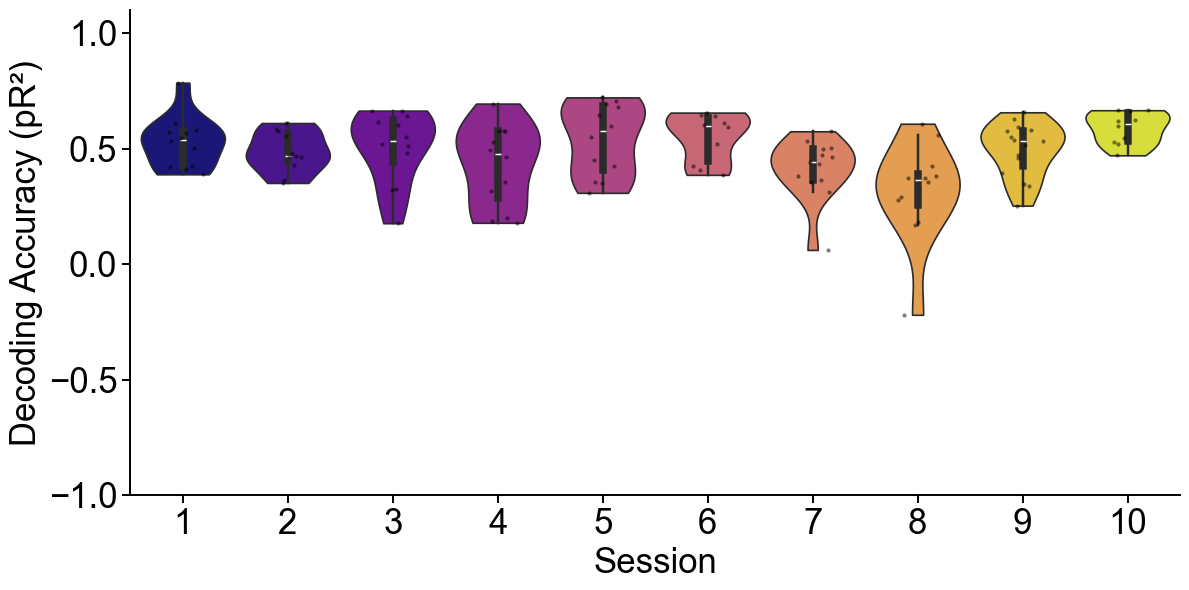

In [5]:
from functions_analysis_online_control_exp.GLM_analysis_spikes_pred import *
 
# Subject we are interested in studying
folder_path   = '/Users/nmt121/Desktop/DATA/S7/'
session_files = session_files7
fsamp = 2048
bin_size_ms = 500 # meets Poisson distribution
alpha_fixed = 0.1 #regularization
outer_kf = KFold(n_splits=10, shuffle=True, random_state=42)
 
# permissive per-fold guards
MIN_BINS_TEST   = 10   # was effectively higher before
MIN_NONZERO_TEST = 5   # relaxed from 20
 
# Outputs
session_results = {}
session_predictions = {}
 
########## RUN GLM ##########
for session, pkl_files in session_files.items():
    session_pR2 = []
    trial_data_list = []
 
    for file in pkl_files:
        glm_data, data, mnpair = load_and_preprocess(file, folder_path, bin_size_ms, fsamp)
        trial_data_list.append(glm_data.T)  # (neurons, time_bins)
 
    concatenated_data = np.hstack(trial_data_list)  # (neurons, bins)
    num_neurons = concatenated_data.shape[0]
 
    for target_idx in range(num_neurons):
        X_all, Y_all = create_glm_data(concatenated_data.T, target_idx)  # X: (bins, feats)
        if X_all is None or Y_all is None:
            continue
 
        #  ignore rare large counts that are not usual, using 99th percentile as cutoff
        y_max = max(2, int(np.floor(np.percentile(Y_all, 99))))
        keep_idx = np.where(Y_all <= y_max)[0]
 
        if keep_idx.size < 10 * MIN_BINS_TEST:
            # not enough bins left to support 10 splits with our minimum test bins
            continue
 
        X = X_all[keep_idx]
        Y = Y_all[keep_idx]
 
        fold_pR2s = []
        all_actual, all_predicted = [], []
 
        for train_idx, test_idx in outer_kf.split(X):

            if len(test_idx) < MIN_BINS_TEST:
                continue
 
            Xtr, Xte = X[train_idx], X[test_idx]
            Ytr, Yte = Y[train_idx], Y[test_idx]
 
            if (Yte > 0).sum() < MIN_NONZERO_TEST:
                continue  
 
            pipe = make_pipeline(StandardScaler(with_mean=True),PoissonRegressor(alpha=alpha_fixed, max_iter=1000))
            pipe.fit(Xtr, Ytr)
 
            Y_pred = pipe.predict(Xte)
            fold_pR2s.append(compute_pR2(Yte, Y_pred))
 
            all_actual.extend(Yte.tolist())
            all_predicted.extend(Y_pred.tolist())
 
        if fold_pR2s:
            session_pR2.append(np.nanmean(fold_pR2s))
            session_predictions.setdefault(session, []).append(
                {'target_idx': target_idx,
                 'actual': np.array(all_actual),
                 'pred':   np.array(all_predicted)}
            )
 
    if session_pR2:
        session_results[session] = session_pR2
 
# === Plot Results (pR² across sessions) ===

plt.figure(figsize=(12,6));
plt.rcParams.update({'font.family':'Arial'})
all_pR2s, all_labels, simplified_labels = [], [], {}

for s in session_results.keys():
    m = re.search(r'(\d+)', s); 
    simplified_labels[s] = str(int(m.group(1))) if m else s
    
for s, vals in session_results.items():
    all_pR2s.extend(vals);
    all_labels.extend([simplified_labels[s]]*len(vals))
    
unique_sessions = sorted(set(all_labels), key=lambda x:int(x))

N = len(unique_sessions)
cmap = plt.get_cmap('plasma')
colors = [cmap(i/max(N-1,1)) for i in range(N)]
palette_dict = dict(zip(unique_sessions, colors))
sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2, palette=palette_dict, cut=0)
sns.stripplot(x=all_labels, y=all_pR2s, color='k', size=3, jitter=0.2, alpha=0.5)
ax = plt.gca()
for sp in ax.spines.values(): sp.set_linewidth(1.4)
plt.tick_params(width=1.4, length=6, labelsize=25)
plt.xlabel("Session", fontsize=25); plt.ylabel("Decoding Accuracy (pR²)", fontsize=25)
plt.ylim([-1, 1.1]); sns.despine(top=True, right=True); plt.tight_layout();
 
# fname = os.path.join('/Users/nmt121/Desktop/Figures/GLM/GLM_good/', "pR2_violin7.pdf")   # or .png, .svg
# plt.savefig(fname, dpi=300, bbox_inches="tight")
plt.show()
 
# # === Example time series ===
# for session in session_predictions.keys():
#     if not session_predictions[session]: continue
#     ap = session_predictions[session][0]
#     actual, pred, tidx = ap['actual'], ap['pred'], ap['target_idx']
#     plt.figure(figsize=(12,4)); plt.rcParams.update({'font.family':'Arial'})
#     plt.plot(actual, label="Actual ", alpha=0.9)
#     plt.plot(pred,   label="Predicted",          alpha=0.7)
#     plt.xlabel("Time bin (concatenated CV folds)", fontsize=14)
#     plt.ylabel("Spike count/bin", fontsize=14)
#     plt.title(f"Session {session} • Target neuron {tidx}", fontsize=14)
#     plt.legend(); plt.tight_layout(); plt.show()
 


### Median value of each day

In [ ]:
# sess_to_vals = {}
# for s, vals in session_results.items():
#     m = re.search(r'(\d+)', s)
#     short = str(int(m.group(1))) if m else s
#     sess_to_vals.setdefault(short, []).extend(vals)

# # Order sessions numerically
# ordered_labels = sorted(sess_to_vals.keys(), key=lambda x: int(x))
# medians1 = [np.nanmedian(sess_to_vals[lab]) for lab in ordered_labels]

# plt.figure(figsize=(10,4))
# plt.rcParams.update({'font.family':'Arial'})
# plt.plot(ordered_labels, medians1, marker='o', linewidth=2)
# plt.xlabel("Session (Day)", fontsize=16)
# plt.ylabel("Median pR²", fontsize=16)
# plt.ylim([-1, 1.1])
# plt.grid(alpha=0.25)
# plt.tight_layout()
# # plt.savefig('/Users/nmt121/Desktop/Figures/GLM/GLM_good/median7.pdf', dpi=300, bbox_inches='tight')
# plt.show()


## Predict spike counts of motoneuron N with the force of the motoneuron pool

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_62305/494688543.py:137: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2, palette=palette_dict, cut=0)


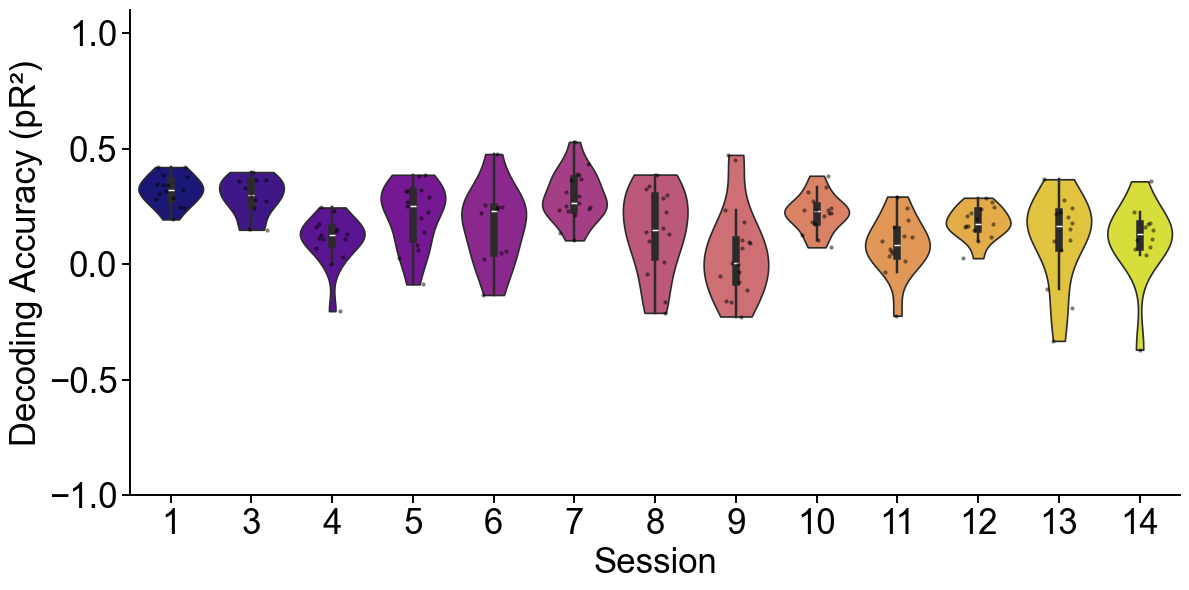

In [6]:
from functions_analysis_online_control_exp.GLM_analysis_force_pred import *

# Subject we are interested in studying
folder_path   = '/Users/nmt121/Desktop/DATA/S1/'
session_files = session_files1
fsamp         = 2048
bin_size_ms   = 500                
alpha_fixed   = 0.1                
outer_kf      = KFold(n_splits=10, shuffle=True, random_state=42)


MIN_BINS_TEST    = 10
MIN_NONZERO_TEST = 5

def preprocess_trial_force(file, folder_path, bin_size_ms, fsamp=2048):
    file_path = os.path.join(folder_path, file)
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    force = np.array(data['Force'])
    if force.ndim == 2:
        force = force.squeeze()
    data_MU = np.array(data['MU'].tolist())

    bin_size_samples = int(bin_size_ms * fsamp / 1000)
    num_timepoints   = force.shape[0]
    num_bins         = num_timepoints // bin_size_samples
    if num_bins <= 0:
        return None, None, None

    binned_spikes = np.add.reduceat(
        data_MU[:, :num_bins * bin_size_samples],
        np.arange(0, num_bins * bin_size_samples, bin_size_samples),
        axis=1
    )
    binned_force = np.add.reduceat(
        force[:num_bins * bin_size_samples],
        np.arange(0, num_bins * bin_size_samples, bin_size_samples)
    ) / bin_size_samples

    mnpair = data.get('Idx_MU_Pair', None)
    try:
        mnpair = mnpair.tolist() if mnpair is not None else None
    except Exception:
        pass
    return binned_spikes, binned_force, mnpair

########## RUN GLM ##########
session_results = {}
session_predictions = {}

for session, pkl_files in session_files.items():
    session_pR2 = []
    force_trials, spike_trials = [], []

    # load & bin all trials
    for file in pkl_files:
        spikes, force, mnpair = preprocess_trial_force(file, folder_path, bin_size_ms, fsamp)
        if spikes is None or force is None:
            continue
        force_trials.append(force)   # (bins,)
        spike_trials.append(spikes)  # (neurons, bins)

    if not force_trials or not spike_trials:
        continue

    concatenated_force  = np.concatenate(force_trials, axis=0)   # (total_bins,)
    concatenated_spikes = np.hstack(spike_trials)                 # (neurons, total_bins)
    num_neurons = concatenated_spikes.shape[0]
    example_plotted = False

    # per neuron
    for neuron_idx in range(num_neurons):
        Y_full = concatenated_spikes[neuron_idx, :].astype(float)
        X_full, Y_full = create_force_glm_data(concatenated_force, Y_full)  # -> (bins, feats), (bins,)
        if X_full is None or Y_full is None:
            continue
        if np.sum(Y_full) < 20:
            continue

        # percentile trim (same logic)
        y_max = max(2, int(np.floor(np.percentile(Y_full, 99))))
        keep_idx = np.where(Y_full <= y_max)[0]
        if keep_idx.size < 10 * MIN_BINS_TEST:
            continue

        X = X_full[keep_idx]
        Y = Y_full[keep_idx]

        # outer CV (no inner grid)
        fold_pR2s = []
        all_actual, all_predicted = [], []

        for train_idx, test_idx in outer_kf.split(X):
            if len(test_idx) < MIN_BINS_TEST:
                continue
            Xtr, Xte = X[train_idx], X[test_idx]
            Ytr, Yte = Y[train_idx], Y[test_idx]
            if (Yte > 0).sum() < MIN_NONZERO_TEST:
                continue

            pipe = make_pipeline(
                StandardScaler(with_mean=True),
                PoissonRegressor(alpha=alpha_fixed, max_iter=1000)
            )
            pipe.fit(Xtr, Ytr)
            Y_pred = pipe.predict(Xte)

            fold_pR2s.append(compute_pR2(Yte, Y_pred))
            all_actual.extend(Yte.tolist())
            all_predicted.extend(Y_pred.tolist())



        if fold_pR2s:
            session_pR2.append(np.nanmean(fold_pR2s))
            session_predictions.setdefault(session, []).append(
                {'target_idx': neuron_idx,
                 'actual': np.array(all_actual),
                 'pred':   np.array(all_predicted)}
            )

    if session_pR2:
        session_results[session] = session_pR2

# === Violin plot (same look) ===
plt.figure(figsize=(12,6)); plt.rcParams.update({'font.family':'Arial'})
all_pR2s, all_labels, simplified_labels = [], [], {}
for s in session_results.keys():
    m = re.search(r'(\d+)', s); simplified_labels[s] = str(int(m.group(1))) if m else s
for s, vals in session_results.items():
    all_pR2s.extend(vals); all_labels.extend([simplified_labels[s]]*len(vals))
unique_sessions = sorted(set(all_labels), key=lambda x:int(x))
N = len(unique_sessions); cmap = plt.get_cmap('plasma')
colors = [cmap(i/max(N-1,1)) for i in range(N)]
palette_dict = dict(zip(unique_sessions, colors))
sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2, palette=palette_dict, cut=0)
sns.stripplot(x=all_labels, y=all_pR2s, color='k', size=3, jitter=0.2, alpha=0.5)
ax = plt.gca()
for sp in ax.spines.values(): sp.set_linewidth(1.4)
plt.tick_params(width=1.4, length=6, labelsize=25)
plt.xlabel("Session", fontsize=25); plt.ylabel("Decoding Accuracy (pR²)", fontsize=25)
plt.ylim([-1, 1.1]); sns.despine(top=True, right=True); plt.tight_layout()
# plt.savefig('/Users/nmt121/Desktop/Figures/GLM/GLM_Good/GLM_force_S4.pdf', dpi=300, bbox_inches='tight')
plt.show()


# to plot concatenated CV folds
# saved_once = False

# for session in session_predictions.keys():
#     if not session_predictions[session]:
#         continue
#     ap = session_predictions[session][0]
#     actual, pred, tidx = ap['actual'], ap['pred'], ap['target_idx']

#     plt.figure(figsize=(12,4)); plt.rcParams.update({'font.family':'Arial'})
#     plt.plot(actual, label="Actual", alpha=0.9)
#     plt.plot(pred,   label="Predicted", alpha=0.7)
#     plt.xlabel("Time bin (concatenated CV folds)", fontsize=14)
#     plt.ylabel("Spike count/bin", fontsize=14)
#     plt.title(f"Session {session} • Target neuron {tidx}", fontsize=14)
#     plt.legend(); plt.tight_layout()

#     if not saved_once:   # save only the very first one
#         plt.savefig('/Users/nmt121/Desktop/Figures/GLM/GLM_Good/trial1.pdf',
#                     dpi=300, bbox_inches='tight')
#         saved_once = True

#     plt.show()


### Median value of each day

In [ ]:
# sess_to_vals = {}
# for s, vals in session_results.items():
#     m = re.search(r'(\d+)', s)
#     short = str(int(m.group(1))) if m else s
#     sess_to_vals.setdefault(short, []).extend(vals)

# # Order sessions numerically
# ordered_labels = sorted(sess_to_vals.keys(), key=lambda x: int(x))
# medians = [np.nanmedian(sess_to_vals[lab]) for lab in ordered_labels]

# plt.figure(figsize=(10,4))
# plt.rcParams.update({'font.family':'Arial'})
# plt.plot(ordered_labels, medians, marker='o', linewidth=2, color='r')
# plt.xlabel("Session (Day)", fontsize=16)
# plt.ylabel("Median pR²", fontsize=16)
# plt.ylim([-1, 1.1])
# plt.grid(alpha=0.25)
# plt.tight_layout()
# # plt.savefig('/Users/nmt121/Desktop/Figures/GLM/GLM_good/medianforce1.pdf', dpi=300, bbox_inches='tight')
# plt.show()


## Comparation of the medians with Spike model and Force model

In [ ]:
# import matplotlib.cm as cm

# days = np.arange(len(medians)) + 1  # day indices

# plt.figure(figsize=(6,6))
# # use a colormap (e.g. plasma, viridis)
# colors = cm.plasma(np.linspace(0,1,len(days)))

# for i, d in enumerate(days):
#     plt.scatter(medians[i], medians1[i], color=colors[i], s=70, label=f"Day {d}")


# plt.xlabel("Median pR² (force)", fontsize=14)
# plt.ylabel("Median pR² (spikes)", fontsize=14)
# plt.axis("equal")
# plt.grid(alpha=0.3)
# plt.xlim([-0.1,np.max(medians1)+0.1])
# plt.ylim([0,np.max(medians1)+0.1])


# # legend with one entry per day
# plt.legend(title="Session", bbox_to_anchor=(1.05, 1), loc="upper left")
# plt.tight_layout()
# plt.savefig('/Users/nmt121/Desktop/Figures/GLM/GLM_good/s7.pdf', dpi=300, bbox_inches='tight')
# plt.show()


## Model with Spikes + Force shows no clear improvement in pR2 

In [ ]:
# from functions_experimental_data_Bräckleinexp.GLM_analysis_spikes_pred import *  # load_and_preprocess, create_glm_data

# folder_path   = '/Users/nmt121/Desktop/DATA/S7/'
# session_files = session_files7
# fsamp         = 2048
# bin_size_ms   = 500
# alpha_fixed   = 0.1
# outer_kf      = KFold(n_splits=10, shuffle=True, random_state=42)

# # permissive per-fold guards
# MIN_BINS_TEST     = 10
# MIN_NONZERO_TEST  = 5

# def bin_force_vector(force_raw, fsamp, bin_size_ms):
#     """Average force within each bin so it aligns with binned spikes."""
#     f = np.asarray(force_raw)
#     if f.ndim > 1:
#         f = f.squeeze()
#     bin_size_samples = int(bin_size_ms * fsamp / 1000)
#     num_bins = f.shape[0] // bin_size_samples
#     if num_bins <= 0:
#         return None
#     binned_force = np.add.reduceat(
#         f[:num_bins * bin_size_samples],
#         np.arange(0, num_bins * bin_size_samples, bin_size_samples)
#     ) / bin_size_samples
#     return binned_force.astype(float)

# session_results = {}
# session_predictions = {}

# ##### RUN GLM #####
# for session, pkl_files in session_files.items():
#     session_pR2 = []
#     trial_data_list = []   # list of (neurons x bins) spike matrices, per trial
#     force_trials    = []   # list of (bins,) force vectors, per trial

#     for file in pkl_files:

#         glm_data, data, mnpair = load_and_preprocess(file, folder_path, bin_size_ms, fsamp)
#         trial_data_list.append(glm_data.T)

#         # get force from the same raw dict and bin it to the same bin size
#         if 'Force' in data:
#             bF = bin_force_vector(data['Force'], fsamp, bin_size_ms)
#             if bF is not None:
#                 force_trials.append(bF)

#     # Require that we have both spikes and force for all trials (safe path)
#     if not trial_data_list or not force_trials:
#         continue

#     # Concatenate across trials along time
#     concatenated_data  = np.hstack(trial_data_list)   # (neurons, total_bins)
#     concatenated_force = np.concatenate(force_trials) # (total_bins,)
#     num_neurons = concatenated_data.shape[0]


#     total_bins = concatenated_data.shape[1]
    
#     # if concatenated_force.shape[0] != total_bins:
#     #     # In case of a rare off-by-one, clip to min length
#     #     L = min(total_bins, concatenated_force.shape[0])
#     #     concatenated_data  = concatenated_data[:, :L]
#     #     concatenated_force = concatenated_force[:L]
#     #     total_bins = L

#     example_plotted = False

#     for target_idx in range(num_neurons):

#         X_spk, Y_all = create_glm_data(concatenated_data.T, target_idx)  # X_spk: (bins, feats_spk), Y_all: (bins,)
#         if X_spk is None or Y_all is None:
#             continue

#         # Append force as an extra covariate (column)
#         F_col = concatenated_force.reshape(-1, 1)  # (bins, 1)

#         if X_spk.shape[0] != F_col.shape[0]:
#             # Shouldn’t happen after clipping above
#             L = min(X_spk.shape[0], F_col.shape[0])
#             X_spk = X_spk[:L]
#             F_col = F_col[:L]
#             Y_all = Y_all[:L]
            
#         X_all = np.hstack([X_spk, F_col])  # (bins, feats_spk + 1)

#         y_max = max(2, int(np.floor(np.percentile(Y_all, 99))))
#         keep_idx = np.where(Y_all <= y_max)[0]
#         if keep_idx.size < 10 * MIN_BINS_TEST:
#             continue

#         X = X_all[keep_idx]
#         Y = Y_all[keep_idx]

#         fold_pR2s = []
#         all_actual, all_predicted = [], []

#         for train_idx, test_idx in outer_kf.split(X):
#             # light-touch fold guards
#             if len(test_idx) < MIN_BINS_TEST:
#                 continue

#             Xtr, Xte = X[train_idx], X[test_idx]
#             Ytr, Yte = Y[train_idx], Y[test_idx]

#             if (Yte > 0).sum() < MIN_NONZERO_TEST:
#                 continue

#             pipe = make_pipeline(
#                 StandardScaler(with_mean=True),
#                 PoissonRegressor(alpha=alpha_fixed, max_iter=1000)
#             )
#             pipe.fit(Xtr, Ytr)
#             Y_pred = pipe.predict(Xte)

#             fold_pR2s.append(compute_pR2(Yte, Y_pred))
#             all_actual.extend(Yte.tolist())
#             all_predicted.extend(Y_pred.tolist())

#         if fold_pR2s:
#             session_pR2.append(np.nanmean(fold_pR2s))
#             session_predictions.setdefault(session, []).append(
#                 {'target_idx': target_idx,
#                  'actual': np.array(all_actual),
#                  'pred':   np.array(all_predicted)}
#             )

#     if session_pR2:
#         session_results[session] = session_pR2

# # === Plot Results (pR² across sessions) ===
# plt.figure(figsize=(12,6)); plt.rcParams.update({'font.family':'Arial'})
# all_pR2s, all_labels, simplified_labels = [], [], {}
# for s in session_results.keys():
#     m = re.search(r'(\d+)', s); simplified_labels[s] = str(int(m.group(1))) if m else s
# for s, vals in session_results.items():
#     all_pR2s.extend(vals); all_labels.extend([simplified_labels[s]]*len(vals))
# unique_sessions = sorted(set(all_labels), key=lambda x:int(x))
# N = len(unique_sessions); cmap = plt.get_cmap('plasma')
# colors = [cmap(i/max(N-1,1)) for i in range(N)]
# palette_dict = dict(zip(unique_sessions, colors))
# sns.violinplot(x=all_labels, y=all_pR2s, inner='box', linewidth=1.2, palette=palette_dict, cut=0)
# sns.stripplot(x=all_labels, y=all_pR2s, color='k', size=3, jitter=0.2, alpha=0.5)
# ax = plt.gca()
# for sp in ax.spines.values(): sp.set_linewidth(1.4)
# plt.tick_params(width=1.4, length=6, labelsize=25)
# plt.xlabel("Session", fontsize=25); plt.ylabel("Decoding Accuracy (pR²)", fontsize=25)
# plt.ylim([-1, 1.1]); sns.despine(top=True, right=True); plt.tight_layout()
# # plt.savefig('/Users/nmt121/Desktop/Figures/GLM/GLM_good/combined7.pdf', dpi=300, bbox_inches='tight')

# plt.show()
